# Práctica 3 · Etapa 1 — Réplica del video: pronóstico del consumo eléctrico con XGBoost

**3201 Modelos Inteligentes de Aprendizaje / 529 Redes Neuronales Modulares** · Maestría y Doctorado en Ciencias e Ingeniería (MyDCI) · Facultad de Ingeniería, Arquitectura y Diseño ·
Universidad Autónoma de Baja California · Ciclo 2026-2 · Versión 6

**Profesores:** Dr. Everardo Inzunza González · Dr. Enrique Efrén García Guerrero · Dr. Oscar Adrián Aguirre Castro

**Fase 0 (verificación, 5 min) y Fase 1 de la sesión** · presupuesto: **5 + 25 min**

---

Este cuaderno reproduce, paso a paso, el video **«Time Series Forecasting with XGBoost — Use python and machine learning to predict energy consumption»** de Rob Mulla (2022, 23 min, https://youtu.be/vV12dGe_Fho) y su cuaderno de Kaggle. Los datos son el consumo eléctrico **horario** de la zona PJM East (EE. UU.), 2002–2018, en megawatts. Las réplicas son **adaptadas**: conservan el método del video y declaran cada diferencia (tabla al final de esta portada). Después de replicarlo, el cuaderno hace tres cosas que el video no hace: **audita** los datos, **corrige** una fuga de información en la detención temprana y **mide** el modelo con las métricas del segundo video del curso («Las Mejores Métricas para Evaluar Modelos de Regresión con Scikit-Learn», Código Máquina, 2022, https://youtu.be/9IZ6OPQWtpw), contra líneas base que dicen si el modelo aporta algo.

| Necesita | Produce |
|---|---|
| `datos/PJME_hourly.csv` (si falta, se descarga de Kaggle) y `datos/DATOS_MENSUALES_EST_2038.xlsx` | Tablas A, B y C · figuras F1 a F4 |

**Cómo leer este cuaderno.** Cada bloque abre con una celda de texto que explica *qué* se hace y *por qué*. Dentro del
código, el comentario a la derecha de cada instrucción dice para qué sirve esa línea. Las salidas marcadas con
**`← Anote`** son las que usted copia en la tabla indicada del manual; el resto sólo se ejecuta y se observa.
Ejecute las celdas **en orden**; si cambia algo, vuelva a ejecutar desde esa celda hacia abajo.

| Minuto del video | Qué hace | Sección de este cuaderno |
|---|---|---|
| 01:06–04:51 | Carga el CSV de Kaggle y grafica la serie | 1.1–1.2 |
| 05:56–07:34 | Parte en entrenamiento/prueba el 1 de enero de 2015; mira una semana | 1.3 |
| 08:06–11:19 | Crea características de calendario y las grafica contra el consumo | 1.4 |
| 11:19–15:18 | Entrena `XGBRegressor` con detención temprana | 1.5 |
| 15:35 | Importancia de las características | 1.6 |
| 17:00–19:55 | Pronostica la prueba y calcula el RMSE | 1.7–1.8 |
| 20:58 | Peores y mejores días | 1.9 |
| 22:01 | «Siguientes pasos» | 1.11 y Etapa 6 |

**Qué cambia respecto del video y del cuaderno de Kaggle (réplicas adaptadas).**

| Aspecto | Video (2022) | Cuaderno de Kaggle | Esta práctica |
|---|---|---|---|
| Orden y horas repetidas del archivo | no se auditan | no se auditan | se ordena el índice y se conserva la primera lectura de cada hora repetida (1.1) |
| `tree_method` | el valor por omisión de su versión (`auto`, anterior a XGBoost 2.0) | igual | `"hist"`, el valor por omisión desde XGBoost 2.0; puede cambiar ligeramente los cortes |
| Semilla | no se ve en pantalla | no se fija | `random_state = 42` en todos los modelos |
| Dispositivo | CPU | CPU | el que decida la Fase 0 (`cpu` por omisión; `cuda` si lo activa) |
| Objetivo | `reg:linear` | `reg:linear` | `reg:squarederror` (mismo criterio; el alias antiguo emite un aviso) |
| API | `early_stopping_rounds` en `fit` (en el minuto 14:11 narra que lo mueve al constructor); `index.weekofyear` | ya en el constructor; `isocalendar().week` | `early_stopping_rounds` en el constructor; `index.isocalendar().week` |
| Semana graficada | del 1 al 8 de enero (ocho días) | límites estrictos (`>` el día 1 y `<` el día 8) | siete días exactos, `[inicio, inicio + 7 d)`: sólo cambian los extremos |

---
## Bloque 0 · Puesta en marcha

Esta celda se ejecuta **siempre primero**, en cualquier entorno. Detecta si está en Google Colab, en el JupyterHub del
laboratorio o en un Jupyter local; localiza la carpeta de la práctica (`P3_SeriesTiempo_v6`, la que descargó de
Classroom); crea `resultados/` con sus subcarpetas sin borrar nada; instala sólo lo que falte; fija la semilla e imprime
las versiones con que se ejecutó. Reproducir un resultado empieza por saber con qué se obtuvo.

**Fase 0 de la sesión.** Además de lo anterior, este primer cuaderno comprueba que los **dos** archivos de datos de la
práctica están completos (su huella MD5 debe coincidir con la del manual) y si su entorno tiene una GPU que XGBoost
pueda usar de verdad. Si algo falla aquí, avise antes de seguir: el resto de la práctica depende de esto.

> **En Colab**, cada cuaderno corre en su propia máquina virtual: los archivos que un cuaderno guarda sólo los ve el
> siguiente si viven en **Google Drive**. Por eso la carpeta de la práctica se sube a *Mi unidad* y esta celda la monta.

In [21]:
# ── Bloque 0 · Puesta en marcha (Etapa 1) ─────────────────────────────────────────────
import sys, os, json, time, hashlib, warnings, subprocess, importlib  # utilidades estándar de Python
from pathlib import Path                                   # rutas que funcionan igual en Windows, Linux y Colab
T0 = time.perf_counter()                                   # cronómetro de este cuaderno
warnings.filterwarnings("ignore", category=FutureWarning)  # oculta sólo avisos de versiones futuras

try:
    import google.colab                                    # este módulo sólo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

CARPETA_PRACTICA = "P3_SeriesTiempo_v6"                    # la carpeta que descargó de Classroom
if EN_COLAB:
    from google.colab import drive                         # acceso a Google Drive desde Colab
    drive.mount("/content/drive")                          # la primera vez pide autorización
    RAIZ_DRIVE = Path("/content/drive/MyDrive")            # «Mi unidad»
    candidatas = [RAIZ_DRIVE / CARPETA_PRACTICA, RAIZ_DRIVE / "Colab Notebooks" / CARPETA_PRACTICA]
    candidatas += sorted(RAIZ_DRIVE.glob(f"*/{CARPETA_PRACTICA}"))  # también un nivel más abajo
else:
    aqui = Path.cwd().resolve()                            # carpeta desde donde se abrió el cuaderno
    candidatas = [aqui, *aqui.parents][:4]                 # el cuaderno vive en notebooks/: se busca hacia arriba
    candidatas += [p / CARPETA_PRACTICA for p in candidatas]
BASE = next((c for c in candidatas if (c / "datos").is_dir() and (c / "notebooks").is_dir()), None)
if BASE is None:
    raise FileNotFoundError("No encuentro la carpeta de la práctica (con datos/ y notebooks/). "
                            "Revise la Sección 4.3 del manual: en Colab súbala completa a «Mi unidad».")
DATOS, RES = BASE / "datos", BASE / "resultados"           # entradas y salidas de la práctica
FIG, TAB, ART = RES / "figuras", RES / "tablas", RES / "artefactos"  # figuras · tablas · archivos intermedios
for carpeta in (FIG, TAB, ART):
    carpeta.mkdir(parents=True, exist_ok=True)             # se crean si faltan; nunca se borra nada

# Bibliotecas: se instala sólo lo que falte (en Colab casi todo viene preinstalado).
NECESARIAS = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "xgboost": "xgboost",
               "matplotlib": "matplotlib", "seaborn": "seaborn", "statsmodels": "statsmodels",
               "openpyxl": "openpyxl", "scipy": "scipy"}
for modulo, paquete in NECESARIAS.items():
    try:
        importlib.import_module(modulo)                    # ¿ya está instalado?
    except ImportError:
        print("Instalando", paquete, "…")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import numpy as np                                         # cálculo numérico con arreglos
import pandas as pd                                        # tablas de datos indexadas por fecha
import matplotlib                                          # motor de gráficas
import matplotlib.pyplot as plt                            # interfaz de gráficas
import sklearn, xgboost as xgb                             # scikit-learn y XGBoost
import seaborn, statsmodels, scipy                         # sólo para registrar sus versiones aquí
import seaborn as sns                                      # gráficas estadísticas (las cajas del video)
import shutil                                              # copiar archivos y buscar programas

def _ver(v):
    return tuple(int("".join(ch for ch in p if ch.isdigit()) or 0) for p in v.split(".")[:2])
assert _ver(sklearn.__version__) >= (1, 4), "Se necesita scikit-learn ≥ 1.4 (root_mean_squared_error)."
assert _ver(xgb.__version__) >= (2, 0), "Se necesita XGBoost ≥ 2.0 (early_stopping_rounds en el constructor)."

SEMILLA = 42                                               # una sola semilla para toda la práctica
np.random.seed(SEMILLA)                                    # fija el azar de numpy
pd.set_option("display.width", 160)                        # tablas anchas sin cortes de renglón
pd.set_option("display.max_columns", 30)
COLORES = {"real": "#15241E", "XGBoost": "#17795C", "SVR": "#D9A21B", "Random Forest": "#9E2B25",
            "Ingenuo": "#9AA7A1", "Ingenuo estacional": "#5E6E67", "Climatología": "#165542"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})  # estilo uniforme de las figuras

def guardar(fig, nombre):
    """Guarda la figura en resultados/figuras/ (PNG, 150 dpi) para insertarla en el manual."""
    ruta = FIG / f"{nombre}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada →", ruta.relative_to(BASE))

def _serializable(v):
    """Convierte tipos de numpy y pandas a tipos de Python; los no finitos (NaN, ±inf) quedan como None."""
    if isinstance(v, dict):
        return {str(k): _serializable(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [_serializable(x) for x in v]
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, np.integer)):
        return int(v)
    if isinstance(v, (float, np.floating)):
        return float(v) if np.isfinite(v) else None
    if isinstance(v, pd.Timestamp):
        return v.isoformat()
    return v

def registrar(clave, valor):
    """Añade un resultado a resultados/registro_P3.json (se acumula entre cuadernos; JSON estricto, sin NaN)."""
    ruta = RES / "registro_P3.json"
    reg = json.loads(ruta.read_text(encoding="utf-8")) if ruta.exists() else {}
    reg[clave] = _serializable(valor)
    ruta.write_text(json.dumps(reg, ensure_ascii=False, indent=1, allow_nan=False), encoding="utf-8")

def md5(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()  # huella del archivo

if EN_COLAB:
    ENTORNO = "Google Colab"
elif "JUPYTERHUB_USER" in os.environ:
    ENTORNO = "JupyterHub"                                 # sesión abierta en el JupyterHub del laboratorio
elif "ai_env" in sys.executable:
    ENTORNO = "Kernel ai_env del laboratorio"              # el mismo kernel, fuera de una sesión del Hub
else:
    ENTORNO = "Jupyter local"
VERSIONES = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
              "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "matplotlib": matplotlib.__version__,
              "seaborn": seaborn.__version__, "statsmodels": statsmodels.__version__, "scipy": scipy.__version__}
registrar("etapa1_entorno", {"entorno": ENTORNO, **VERSIONES})
print("Entorno        :", ENTORNO)                         # ← Anote (Tabla A)
print("Carpeta base   :", BASE)
for k, v in VERSIONES.items():
    print(f"{k:<15}:", v)                                  # ← Anote (Tabla A): Python, scikit-learn, XGBoost y pandas

Entorno        : Jupyter local
Carpeta base   : C:\Users\Diana\git\Course_RedesNeuronales_2026\PR3_TimeSeries\P3_SeriesTiempo_v6
python         : 3.12.15
numpy          : 2.5.4
pandas         : 3.1.0
scikit-learn   : 1.9.1
xgboost        : 3.4.1
matplotlib     : 3.11.2
seaborn        : 0.13.2
statsmodels    : 0.15.0
scipy          : 1.18.1


In [2]:
# ── Fase 0 · Datos y GPU ──────────────────────────────────────────────────────────────────
ARCHIVO_PJME = DATOS / "PJME_hourly.csv"                   # consumo horario de PJM East (Kaggle, licencia CC0)
ARCHIVO_2038 = DATOS / "DATOS_MENSUALES_EST_2038.xlsx"     # precipitación mensual (Etapas 2 a 6)
if not ARCHIVO_PJME.exists():                              # sólo si no vino en el paquete de Classroom
    print("No encuentro PJME_hourly.csv: lo descargo de Kaggle (conjunto público, ~12 MB comprimido)…")
    try:
        import kagglehub                                   # cliente oficial de Kaggle (preinstalado en Colab)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    carpeta = Path(kagglehub.dataset_download("robikscube/hourly-energy-consumption"))  # no pide credenciales
    shutil.copy2(carpeta / "PJME_hourly.csv", ARCHIVO_PJME)  # lo deja en datos/ para las demás etapas
for archivo, esperado in [(ARCHIVO_PJME, "5908f274ab73d5eaeb88654a8d238df3"),
                          (ARCHIVO_2038, "79db93f4acdb00dee34cdd85c70d62ad")]:
    huella = md5(archivo)
    print(f"{archivo.name:<32} MD5 {huella} {'✓' if huella == esperado else '✗ NO COINCIDE: avise'}")  # ← Anote (Tabla A)

USAR_GPU = False                                           # cámbielo a True si quiere entrenar en GPU (la referencia del profesor usa CPU)
try:                                                       # prueba mínima: un árbol con device="cuda" y se comprueba dónde se entrenó de verdad
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _sonda = xgb.XGBRegressor(n_estimators=1, max_depth=1, device="cuda").fit([[0.0], [1.0]], [0.0, 1.0])
    _dispositivo_real = json.loads(_sonda.get_booster().save_config())["learner"]["generic_param"]["device"]
    gpu_disponible = _dispositivo_real.startswith("cuda")  # sin GPU visible, XGBoost cae a la CPU sin lanzar error
    if not gpu_disponible:
        print("XGBoost no encontró una GPU visible: el árbol de prueba se entrenó en", _dispositivo_real)
except Exception as e:                                     # sin soporte CUDA en la instalación o sin controlador: también cuenta como «no disponible»
    gpu_disponible = False
    print("Sin GPU para XGBoost:", str(e).splitlines()[0][:120])
DISPOSITIVO = "cuda" if (USAR_GPU and gpu_disponible) else "cpu"  # dónde entrenará XGBoost
print("GPU utilizable por XGBoost:", gpu_disponible, "· se usará:", DISPOSITIVO)  # ← Anote (Tabla A)
registrar("etapa1_fase0", {"gpu_disponible": gpu_disponible, "dispositivo": DISPOSITIVO})

PJME_hourly.csv                  MD5 5908f274ab73d5eaeb88654a8d238df3 ✓
DATOS_MENSUALES_EST_2038.xlsx    MD5 79db93f4acdb00dee34cdd85c70d62ad ✓
XGBoost no encontró una GPU visible: el árbol de prueba se entrenó en cpu
GPU utilizable por XGBoost: False · se usará: cpu


---
## 1.1 Carga de los datos (como en el video, 03:15–04:51)

El archivo tiene dos columnas: `Datetime` (fecha y hora) y `PJME_MW` (consumo medio de esa hora, en MW). El video lo
lee, convierte la fecha en índice y la pasa a tipo `datetime`. Es exactamente lo que hace la primera celda; la forma
del archivo se imprime **antes** de convertir la fecha en índice, porque después `shape` ya no cuenta esa columna.

In [3]:
df = pd.read_csv(ARCHIVO_PJME)                # el CSV tal cual viene de Kaggle
print("Filas y columnas del CSV:", df.shape)  # ← Anote (Tabla B)
df = df.set_index("Datetime")                 # la fecha y hora como índice (video, 03:45)
df.index = pd.to_datetime(df.index)           # de texto a fecha (video, 04:51)
df.head()

Filas y columnas del CSV: (145366, 2)


,PJME_MW
Datetime,
2002-12-31 01:00:00,26498.0
2002-12-31 02:00:00,25147.0
2002-12-31 03:00:00,24574.0
2002-12-31 04:00:00,24393.0
2002-12-31 05:00:00,24860.0


### Auditoría que el video no hace

Antes de modelar conviene preguntar tres cosas que el video da por supuestas: ¿está el archivo **en orden
cronológico**?, ¿hay **horas repetidas**?, ¿**faltan horas**? Con un modelo de puro calendario no importa mucho; en
cuanto se usen rezagos (Etapas 2 a 6), un archivo desordenado produce rezagos falsos sin ningún aviso.

In [4]:
print("¿Orden cronológico?        :", df.index.is_monotonic_increasing)  # ← Anote (Tabla B)
print("Primera fila del archivo   :", df.index[0], "· fecha más antigua:", df.index.min())
repetidas = df.index[df.index.duplicated(keep=False)].unique()  # marcas de hora que aparecen dos veces
print("Marcas de hora repetidas   :", len(repetidas), "→", [f"{t:%Y-%m-%d %H:%M}" for t in repetidas])  # ← Anote (Tabla B)
df = df.sort_index()                         # orden cronológico
df = df[~df.index.duplicated(keep="first")]  # conserva la primera de cada hora repetida
completas = pd.date_range(df.index.min(), df.index.max(), freq="h")  # la rejilla horaria ideal
print("Horas faltantes            :", len(completas.difference(df.index)))  # ← Anote (Tabla B)
print("Periodo                    :", df.index.min(), "→", df.index.max())
bajos = df[df["PJME_MW"] < 19_000]           # valores atípicamente bajos (los marca la parte 2 del video)
print("Horas con menos de 19 000 MW:", len(bajos), "· entre", bajos.index.min(), "y", bajos.index.max())  # ← Anote (Tabla B)

¿Orden cronológico?        : False
Primera fila del archivo   : 2002-12-31 01:00:00 · fecha más antigua: 2002-01-01 01:00:00
Marcas de hora repetidas   : 4 → ['2014-11-02 02:00', '2015-11-01 02:00', '2016-11-06 02:00', '2017-11-05 02:00']
Horas faltantes            : 30
Periodo                    : 2002-01-01 01:00:00 → 2018-08-03 00:00:00
Horas con menos de 19 000 MW: 15 · entre 2012-10-29 23:00:00 y 2012-10-31 05:00:00


> **Decisión metodológica 1.** Se ordena el índice y se conserva la primera lectura de cada hora repetida. Mire las
> fechas de las horas repetidas y faltantes: si caen en los cambios de horario de verano de EE. UU. (marzo/abril y
> octubre/noviembre), ésa es una **hipótesis** que usted puede comprobar, no un dato del archivo. Las horas con menos
> de 19 000 MW se concentran en unos pocos días consecutivos: localícelos e investigue qué ocurrió esos días antes de
> decidir si son error o evento real. En esta etapa se dejan como están, igual que en el video.

---
## 1.2 La serie completa y 1.3 la partición entrenamiento/prueba (video, 05:56)

El video separa por fecha: todo lo anterior al **1 de enero de 2015** entrena y lo posterior se usa como prueba. Es una
partición temporal: el futuro nunca entrena. La celda imprime cuántas horas quedan de cada lado y qué fracción es la
prueba. La semana que se grafica son **siete días exactos**, `[inicio, inicio + 7 d)`; el video toma del 1 al 8 de
enero, que son ocho.

Entrenamiento: 113925 h · prueba: 31437 h (21.6% del total)
Figura guardada → resultados\figuras\F01_pjme_serie_particion_semana.png


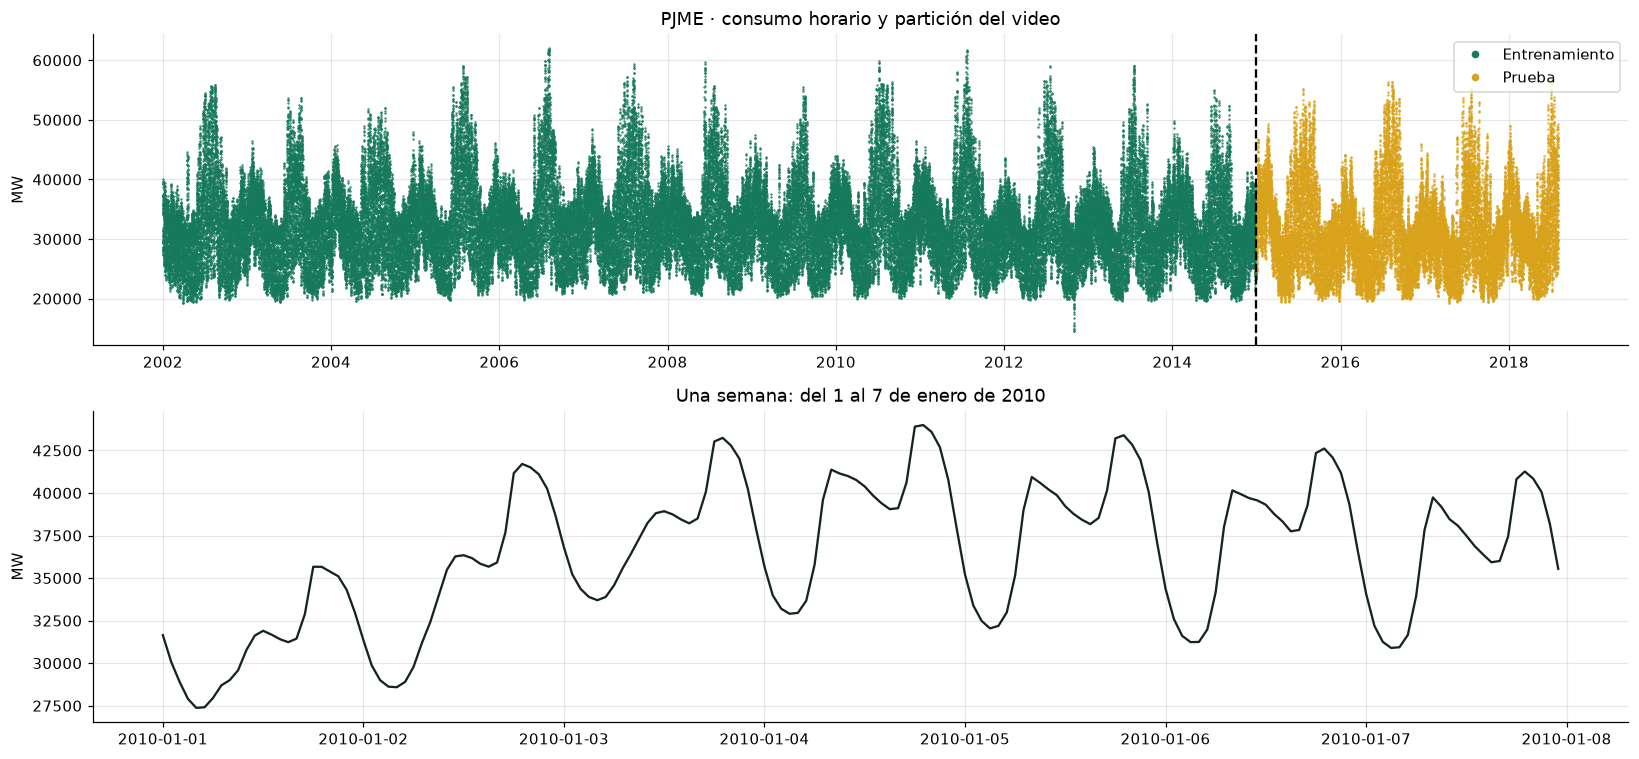

In [5]:
CORTE = "2015-01-01"                                        # fecha de corte del video
train = df.loc[df.index < CORTE]                            # 2002–2014
test = df.loc[df.index >= CORTE]                            # 2015–2018
print(f"Entrenamiento: {len(train)} h · prueba: {len(test)} h ({len(test) / len(df):.1%} del total)")  # ← Anote (Tabla B)

def semana_desde(serie, inicio):
    """Las 7 × 24 horas que empiezan en `inicio`: intervalo [inicio, inicio + 7 días)."""
    inicio = pd.Timestamp(inicio)
    return serie.loc[(serie.index >= inicio) & (serie.index < inicio + pd.Timedelta(days=7))]

fig, ax = plt.subplots(2, 1, figsize=(15, 7))
ax[0].plot(train.index, train["PJME_MW"], ".", ms=1, color="#17795C", label="Entrenamiento")  # puntos, como el video
ax[0].plot(test.index, test["PJME_MW"], ".", ms=1, color="#D9A21B", label="Prueba")
ax[0].axvline(pd.Timestamp(CORTE), color="black", ls="--")  # línea del corte
ax[0].set(title="PJME · consumo horario y partición del video", ylabel="MW")
ax[0].legend(markerscale=8)
semana = semana_desde(df["PJME_MW"], "2010-01-01")          # una semana (video, 07:34)
ax[1].plot(semana.index, semana.values, color="#15241E")
ax[1].set(title="Una semana: del 1 al 7 de enero de 2010", ylabel="MW")
fig.tight_layout()
guardar(fig, "F01_pjme_serie_particion_semana")             # → Figura F1 del manual
plt.show()

---
## 1.4 Características de calendario (video, 08:06–11:19)

El modelo del video **no usa el pasado del consumo**: sólo la fecha. De cada marca de tiempo saca la hora, el día de la
semana, el trimestre, el mes, el año y el día del año. La función crea además el día del mes y la semana del año, que
el video calcula pero no usa.

> **Cambio respecto del código original.** `df.index.weekofyear` se eliminó en pandas 2.0; su reemplazo es
> `df.index.isocalendar().week`, que es lo que usa el cuaderno de Kaggle actualizado.

C:\Users\Diana\AppData\Local\Temp\ipykernel_15812\917101490.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["dayofweek"] = df.index.dayofweek    # 0 = lunes … 6 = domingo
C:\Users\Diana\AppData\Local\Temp\ipykernel_15812\917101490.py:9: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df["dayofyear"] = df.index.dayofyear    # 1–366: estacionalidad fina
C:\Users\Diana\AppData\Local\Temp\ipykernel_15812\917101490.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["dayofweek"] = df.index.dayofweek    # 0 = lunes … 6 = domingo
C:\Users\Diana\AppData\Local\Temp\ipykernel_15812\917101490.py:9: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year in

Figura guardada → resultados\figuras\F02_pjme_relacion_hora_mes.png


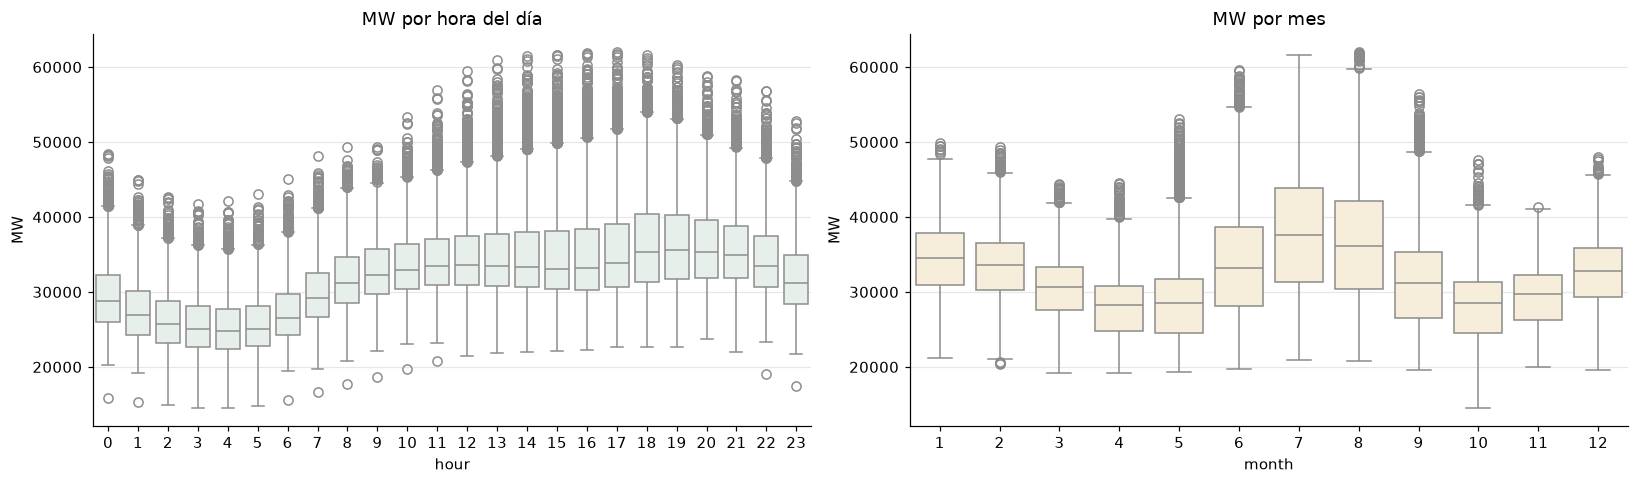

In [8]:
def create_features(df):
    """Crea características de calendario a partir del índice de fechas (función del video)."""
    df = df.copy()                          # no modifica el original
    df["hour"] = df.index.hour              # 0–23
    df["dayofweek"] = df.index.dayofweek    # 0 = lunes … 6 = domingo
    df["quarter"] = df.index.quarter        # 1–4
    df["month"] = df.index.month            # 1–12
    df["year"] = df.index.year              # tendencia de largo plazo
    df["dayofyear"] = df.index.dayofyear    # 1–366: estacionalidad fina
    df["dayofmonth"] = df.index.day         # creada pero no usada en el video
    df["weekofyear"] = df.index.isocalendar().week.astype(int).values  # reemplazo de .weekofyear
    return df

df = create_features(df)
train, test = create_features(train), create_features(test)
FEATURES = ["dayofyear", "hour", "dayofweek", "quarter", "month", "year"]  # las seis del video
TARGET = "PJME_MW"
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=df, x="hour", y=TARGET, ax=ax[0], color="#E6F0EB")  # consumo por hora del día
ax[0].set(title="MW por hora del día", ylabel="MW")
sns.boxplot(data=df, x="month", y=TARGET, ax=ax[1], color="#FAF0D6")  # consumo por mes
ax[1].set(title="MW por mes", ylabel="MW")
fig.tight_layout()
guardar(fig, "F02_pjme_relacion_hora_mes")  # → Figura F2 del manual
plt.show()

---
## 1.5 El modelo del video: `XGBRegressor` con detención temprana

XGBoost construye árboles de decisión **en secuencia**: cada árbol nuevo se ajusta a los residuos que dejaron los
anteriores, y su contribución se multiplica por la tasa de aprendizaje (`learning_rate`). Con 1 000 árboles posibles y
`early_stopping_rounds=50`, el entrenamiento se detiene si el error del **último** conjunto de `eval_set` no mejora en
50 árboles seguidos. Conviene distinguir dos números que suelen confundirse: las **rondas entrenadas**
(`num_boosted_rounds()`, cuántos árboles llegó a construir antes de detenerse) y los **árboles usados para predecir**
(`best_iteration + 1`, los que había cuando el error de validación fue mínimo; los 50 de paciencia se descartan).

**Réplica A · el cuaderno publicado en Kaggle.** Usa `max_depth=3` y `base_score=0.5`. El objetivo original
`reg:linear` es un alias obsoleto de `reg:squarederror` (mismo error cuadrático); se usa el nombre vigente para evitar
el aviso.

In [9]:
def arboles(modelo):
    """(árboles usados para predecir, rondas entrenadas) de un XGBRegressor con detención temprana."""
    return int(modelo.best_iteration) + 1, int(modelo.get_booster().num_boosted_rounds())

t0 = time.perf_counter()
reg = xgb.XGBRegressor(base_score=0.5, booster="gbtree",  # intercepto fijo, árboles como aprendices
                       n_estimators=1000,                 # máximo de árboles
                       early_stopping_rounds=50,          # paciencia de la detención temprana
                       objective="reg:squarederror",      # = 'reg:linear' del original
                       max_depth=3, learning_rate=0.01,   # árboles chicos, pasos pequeños
                       tree_method="hist", device=DISPOSITIVO, random_state=SEMILLA)
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],  # ¡la prueba vigila la detención! (como el video)
        verbose=100)                                      # imprime el error cada 100 árboles
t_A = time.perf_counter() - t0
usados_A, rondas_A = arboles(reg)
print(f"Réplica A: {usados_A} árboles usados · {rondas_A} rondas entrenadas · {t_A:.1f} s")  # ← Anote (Tabla B: rondas y árboles)

[0]	validation_0-rmse:32605.20976	validation_1-rmse:31658.00911
[100]	validation_0-rmse:12584.62301	validation_1-rmse:11749.23404
[200]	validation_0-rmse:5836.22505	validation_1-rmse:5367.06037
[300]	validation_0-rmse:3923.63798	validation_1-rmse:4024.20983
[400]	validation_0-rmse:3446.65453	validation_1-rmse:3853.62815
[500]	validation_0-rmse:3285.43858	validation_1-rmse:3806.79585
[600]	validation_0-rmse:3205.58950	validation_1-rmse:3774.22930
[700]	validation_0-rmse:3152.49967	validation_1-rmse:3753.51278
[800]	validation_0-rmse:3112.40492	validation_1-rmse:3736.19857
[900]	validation_0-rmse:3082.75871	validation_1-rmse:3725.67662
[999]	validation_0-rmse:3054.96167	validation_1-rmse:3722.93413
Réplica A: 953 árboles usados · 1000 rondas entrenadas · 0.9 s


**Réplica B · lo que se ve en pantalla en el video.** En el video (15:18) el modelo se crea sin `max_depth`, así que usa
el valor por omisión (6). El autor narra que el entrenamiento **se detuvo después de 436 árboles** (15:18) y obtiene un
**RMSE de prueba de 3714.53 MW** (19:55). La cifra narrada es la de las rondas entrenadas, no la de los árboles usados
para predecir: compárela con su columna de rondas. Desde XGBoost 2.0 el intercepto `base_score` se estima
automáticamente con los datos; para reproducir el comportamiento de la versión que usó el video se fija en 0.5.

In [10]:
from sklearn.metrics import root_mean_squared_error
reg_B = xgb.XGBRegressor(base_score=0.5, n_estimators=1000, early_stopping_rounds=50, learning_rate=0.01,
                         tree_method="hist", device=DISPOSITIVO, random_state=SEMILLA)  # max_depth por omisión = 6
reg_B.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
rmse_B = root_mean_squared_error(y_test, reg_B.predict(X_test))
usados_B, rondas_B = arboles(reg_B)
print(f"Réplica B: {usados_B} árboles usados · {rondas_B} rondas entrenadas (video: se detuvo tras 436) · "
      f"RMSE {rmse_B:.2f} MW (video: 3714.53) · n = {len(y_test)} h")  # ← Anote (Tabla B)

Réplica B: 381 árboles usados · 431 rondas entrenadas (video: se detuvo tras 436) · RMSE 3712.70 MW (video: 3714.53) · n = 31437 h


---
## 1.6 Importancia de las características (video, 15:35)

`feature_importances_` reporta, para cada característica, la ganancia promedio que aportan los cortes hechos con ella
(tipo `gain`, el valor por omisión con árboles). Como advierte el propio video, si dos características están
correlacionadas (el mes y el día del año) se reparten la importancia: **no** es la importancia individual de cada una.

Figura guardada → resultados\figuras\F03_pjme_importancia.png


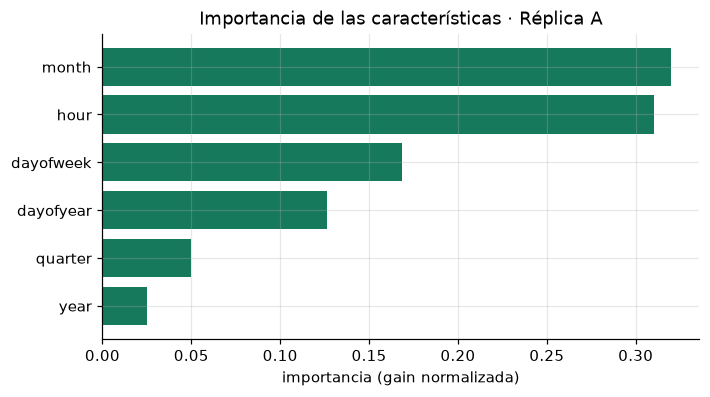

             month  hour  dayofweek  dayofyear  quarter   year
importancia   0.32  0.31      0.169      0.126     0.05  0.025


In [11]:
fi = pd.DataFrame(data=reg.feature_importances_, index=reg.feature_names_in_, columns=["importancia"])
fi = fi.sort_values("importancia")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(fi.index, fi["importancia"], color="#17795C")  # barras horizontales, como el video
ax.set(title="Importancia de las características · Réplica A", xlabel="importancia (gain normalizada)")
guardar(fig, "F03_pjme_importancia")                   # → Figura F3 del manual
plt.show()
print(fi[::-1].round(3).T.to_string())                 # ← Anote (Tabla B): las dos más importantes

---
## 1.7 Pronóstico sobre la prueba (video, 17:00–18:46)

Fíjese en **cómo** pronostica este modelo: desde un **origen fijo** (el 1 de enero de 2015) produce las 24 horas de
cada día de los casi cuatro años de prueba sin mirar ningún dato posterior al origen, porque sólo necesita el
calendario. Es un pronóstico de horizonte largo y de información mínima. La semana que se grafica son siete días
exactos, `[inicio, inicio + 7 d)`.

Figura guardada → resultados\figuras\F04_pjme_pronostico_prueba_y_semana.png


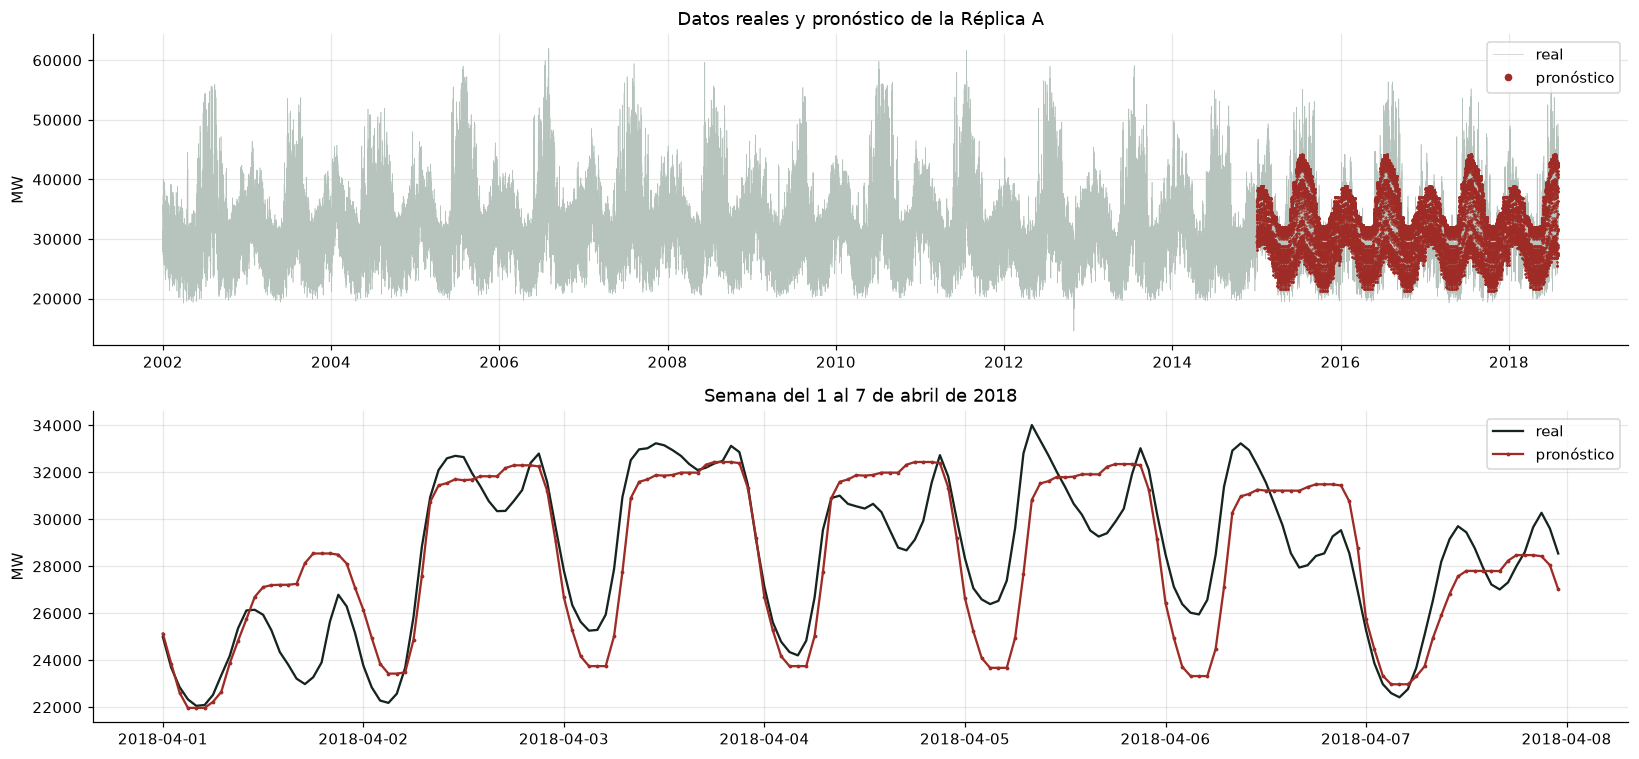

In [12]:
test = test.copy()
test["prediction"] = reg.predict(X_test)             # pronóstico de la Réplica A
fig, ax = plt.subplots(2, 1, figsize=(15, 7))
ax[0].plot(df.index, df[TARGET], color="#B7C4BD", lw=0.4, label="real")  # toda la serie
ax[0].plot(test.index, test["prediction"], ".", ms=1, color="#9E2B25", label="pronóstico")
ax[0].set(title="Datos reales y pronóstico de la Réplica A", ylabel="MW")
ax[0].legend(markerscale=8)
sem = semana_desde(test, "2018-04-01")               # una semana de abril de 2018 (video, 18:46)
ax[1].plot(sem.index, sem[TARGET], color="#15241E", label="real")
ax[1].plot(sem.index, sem["prediction"], ".-", color="#9E2B25", ms=3, label="pronóstico")
ax[1].set(title="Semana del 1 al 7 de abril de 2018", ylabel="MW")
ax[1].legend()
fig.tight_layout()
guardar(fig, "F04_pjme_pronostico_prueba_y_semana")  # → Figura F4 del manual
plt.show()

---
## 1.8 Métricas de regresión (video 2) y la cifra del video

El video sólo calcula el **RMSE** (19:55). El segundo video del curso (Código Máquina, 2022) explica seis métricas con un
ejemplo mínimo: valores reales `[1, 2, 3, 4, 5]` y una predicción que acierta todo menos el último valor, `[1, 2, 3, 4, −5]`.
La primera celda reproduce ese ejemplo y **comprueba** que se obtienen los mismos números del video; la segunda aplica
las mismas métricas al consumo eléctrico.

> **Cambio respecto del video 2.** El video calcula el RMSE con `mean_squared_error(..., squared=False)`. Ese parámetro
> se eliminó en scikit-learn 1.6; hoy se usa `root_mean_squared_error` (disponible desde la 1.4).

In [13]:
from sklearn.metrics import (max_error, mean_absolute_error, mean_squared_error, root_mean_squared_error,
                             r2_score, mean_absolute_percentage_error, median_absolute_error)

def metricas_regresion(y, p):
    """Las métricas del video 2 (más MAPE y MedAE) para un pronóstico p de los valores reales y."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"n": int(len(y)),                       # cuántos valores se evaluaron
            "MaxErr": max_error(y, p),              # el peor error absoluto
            "MAE": mean_absolute_error(y, p),       # promedio de |error|
            "MSE": mean_squared_error(y, p),        # promedio de error²
            "RSS": float(np.sum((y - p) ** 2)),     # suma de error² (= n · MSE)
            "RMSE": root_mean_squared_error(y, p),  # raíz del MSE, en unidades de y
            "R2": r2_score(y, p),                   # 1 − RSS/TSS: reducción relativa del error cuadrático frente a predecir la media
            "MAPE_%": 100 * mean_absolute_percentage_error(y, p),  # en porcentaje; sólo si y nunca vale 0
            "MedAE": median_absolute_error(y, p)}   # mediana de |error|

ejemplo = metricas_regresion([1, 2, 3, 4, 5], [1, 2, 3, 4, -5])  # el ejemplo del video 2
esperado = {"MaxErr": 10, "MAE": 2, "MSE": 20, "RSS": 100, "RMSE": 4.47, "R2": -9.0}
for k, v in esperado.items():
    assert abs(ejemplo[k] - v) < 0.01, f"{k} no coincide con el video"  # si falla, algo está mal instalado
print({k: round(ejemplo[k], 2) for k in esperado}, "✓ coinciden con el video 2")  # ← Anote (Tabla C): primera fila
print("Número de valores evaluados:", ejemplo["n"])

{'MaxErr': 10.0, 'MAE': 2.0, 'MSE': 20.0, 'RSS': 100.0, 'RMSE': 4.47, 'R2': -9.0} ✓ coinciden con el video 2
Número de valores evaluados: 5


> **Sobre el R² del ejemplo.** −9 no es un error: el R² compara el error cuadrático del modelo con el de predecir
> siempre la media de los valores reales, y aquí el modelo es diez veces peor que esa regla. En toda la práctica el R²
> se lee así: como la **reducción relativa del error cuadrático frente a predecir la media del bloque evaluado**. El
> video 2 desaconseja usar el R² con modelos no lineales, con base en Spiess y Neumeyer (2010); aquí se usa como medida
> relativa del error frente a la media, sin leerlo como «varianza explicada» (esa segunda lectura es la que deja de
> valer fuera de la regresión lineal). Discuta este matiz en su reporte.

### ¿Es bueno un RMSE de ese tamaño? Líneas base con la misma información

Un número suelto no dice nada. El modelo del video usa **sólo el calendario** y pronostica desde un **origen fijo**
todo el bloque de prueba; su comparación justa es una regla con la misma información y el mismo origen: el **perfil de
calendario**, la media del consumo de entrenamiento para cada combinación de mes, día de la semana y hora. Como
referencia adicional se calculan dos reglas que **sí** usan el pasado reciente y que, por eso, juegan con otra
información y otro horizonte: repetir la misma hora de ayer (ingenuo 24 h) o de la semana pasada (ingenuo 168 h). Esas
dos reglas exigen observar el consumo real a medida que avanza la prueba: es una **evaluación secuencial con
actualización**. En la hora $t-1$ se pronostica la hora $t$ con $y(t-24)$ o con $y(t-168)$: el **horizonte es una
hora** en ambos casos, y 24 y 168 son **rezagos** (qué dato del pasado se copia), no horizontes. Los cinco métodos se
miden sobre las **mismas horas**: se descartan las pocas horas de prueba sin referencia ingenua, y la tabla dice
cuántas quedaron.

In [14]:
perfil = train.groupby(["month", "dayofweek", "hour"])[TARGET].mean()  # 12 × 7 × 24 = 2 016 promedios
llave = pd.MultiIndex.from_arrays([test["month"], test["dayofweek"], test["hour"]])
pred_perfil = perfil.reindex(llave).values                 # el promedio que corresponde a cada hora de prueba
serie = df[TARGET]

ing_24 = (test.index - pd.Timedelta(hours=24)).map(serie)  # la misma hora del día anterior
ing_168 = (test.index - pd.Timedelta(hours=168)).map(serie).to_numpy()  # la misma hora de la semana anterior
validas = ~(pd.isna(ing_24) | pd.isna(ing_168))          # descarta las pocas horas sin referencia
print("Horas de prueba evaluadas en la Tabla C:", int(validas.sum()), "de", len(test))  # ← Anote (Tabla C): n

metodos = {"XGBoost · Réplica A (video)": test["prediction"].values, "XGBoost · Réplica B (en pantalla)": reg_B.predict(X_test),
           "Perfil de calendario": pred_perfil, "Ingenuo 24 h": ing_24, "Ingenuo 168 h": ing_168}
tabla_C = pd.DataFrame({n: metricas_regresion(y_test.values[validas], np.asarray(p)[validas])
                        for n, p in metodos.items()}).T
tabla_C.round({"n": 0, "MaxErr": 0, "MAE": 1, "MSE": 0, "RSS": 0, "RMSE": 1, "R2": 4, "MAPE_%": 2, "MedAE": 1})  # ← Anote (Tabla C)

Horas de prueba evaluadas en la Tabla C: 31429 de 31437


,n,MaxErr,MAE,MSE,RSS,RMSE,R2,MAPE_%,MedAE
XGBoost · Réplica A (video),31429.0,18880.0,2898.6,13861185.0,4.356432e+11,3723.1,0.6668,9.15,2322.3
XGBoost · Réplica B (en pantalla),31429.0,20590.0,2750.5,13786127.0,4.332842e+11,3713.0,0.6686,8.49,1987.6
Perfil de calendario,31429.0,16573.0,3016.8,14469084.0,4.547488e+11,3803.8,0.6521,9.71,2532.2
Ingenuo 24 h,31429.0,21131.0,2209.4,9153325.0,2.876799e+11,3025.4,0.7799,6.96,1595.0
Ingenuo 168 h,31429.0,22067.0,3400.4,21582492.0,6.783161e+11,4645.7,0.4811,10.54,2522.0


> **Cómo leerlo.** Que la regla «la misma hora de ayer» tenga menor error que el modelo **no** significa que el modelo
> sea inútil: significa que comparar exige el mismo origen, el mismo horizonte y la misma información. El modelo de
> calendario puede pronosticar todo 2027 hoy mismo; el ingenuo de 24 h no puede pronosticar más allá de mañana. La
> pregunta correcta es si el modelo le gana a su competidor con la misma información (el perfil de calendario) y por
> cuánto. Los RMSE de la Tabla C se calculan sobre las horas con referencia ingenua; los de la Tabla B, sobre toda la
> prueba. Por eso pueden diferir en décimas: anote el *n* junto a cada cifra.

---
## 1.9 Peores y mejores días (video, 20:58)

In [15]:
test["error"] = np.abs(test[TARGET] - test["prediction"])  # error absoluto por hora
test["date"] = test.index.date
error_dia = test.groupby("date")["error"].mean()           # error absoluto medio de cada día
print("Cinco PEORES días:\n", error_dia.sort_values(ascending=False).head(5).round(1).to_string())  # ← Anote (Tabla B: el peor día y su error medio)
print("\nCinco MEJORES días:\n", error_dia.sort_values().head(5).round(1).to_string())

Cinco PEORES días:
 date
2016-08-13    12726.5
2016-08-14    12701.0
2016-09-10    12089.5
2015-02-20    11053.1
2016-09-09    10818.8

Cinco MEJORES días:
 date
2017-10-24    322.6
2015-10-28    416.3
2016-10-27    536.8
2015-05-06    552.7
2018-05-16    570.7


---
## 1.10 La fuga de información del video y su corrección

En el video, el conjunto de prueba está dentro de `eval_set` y es **el último**, así que es el que decide cuándo parar
(13:36: *«stop early if the test set does not improve after 50 trees»*). El número de árboles se elige, por tanto,
mirando la prueba: la prueba deja de ser una estimación independiente del error futuro, aunque la cifra cambie poco.

**Corrección, en dos pasos.** (1) **Selección:** se separa del entrenamiento su último año (2014) como validación; un
modelo ajustado con 2002–2013 y vigilado por 2014 dice **cuántos árboles** usar. (2) **Reentrenamiento:** con ese
número de árboles, y ya sin detención temprana, se reentrena con **todo** el entrenamiento (2002–2014), la misma
ventana de ajuste que usó la Réplica A. Así la única diferencia entre la Réplica A y el modelo corregido es *quién
eligió el número de árboles*; la prueba (2015–2018) no interviene en ninguna decisión y se mira una sola vez al final.

In [16]:
X_tr2, y_tr2 = X_train.loc[X_train.index < "2014-01-01"], y_train.loc[y_train.index < "2014-01-01"]  # 2002–2013
X_val, y_val = X_train.loc[X_train.index >= "2014-01-01"], y_train.loc[y_train.index >= "2014-01-01"]  # 2014
reg_sel = xgb.XGBRegressor(base_score=0.5, booster="gbtree", n_estimators=1000, early_stopping_rounds=50,
                           objective="reg:squarederror", max_depth=3, learning_rate=0.01,
                           tree_method="hist", device=DISPOSITIVO, random_state=SEMILLA)
reg_sel.fit(X_tr2, y_tr2, eval_set=[(X_tr2, y_tr2), (X_val, y_val)], verbose=False)  # paso 1: 2014 vigila
usados_C, rondas_C = arboles(reg_sel)       # cuántos árboles eligió la validación
rmse_val_C = root_mean_squared_error(y_val, reg_sel.predict(X_val))  # error en el año de validación
reg_C = xgb.XGBRegressor(base_score=0.5, booster="gbtree", n_estimators=usados_C,  # paso 2: ese número, fijo
                         objective="reg:squarederror", max_depth=3, learning_rate=0.01,
                         tree_method="hist", device=DISPOSITIVO, random_state=SEMILLA)
reg_C.fit(X_train, y_train, verbose=False)  # reentrena con 2002–2014, sin mirar la prueba
pred_C = reg_C.predict(X_test)              # la prueba se usa una sola vez
m_A = metricas_regresion(y_test, test["prediction"]); m_C = metricas_regresion(y_test, pred_C)
print(f"Réplica A (la prueba vigila)        : {usados_A:4d} árboles usados ({rondas_A} rondas) · "
      f"RMSE de prueba {m_A['RMSE']:.1f} MW · n = {m_A['n']}")  # ← Anote (Tabla B)
print(f"Selección con 2014 (ajuste 2002–2013): {usados_C:4d} árboles elegidos ({rondas_C} rondas) · "
      f"RMSE de validación {rmse_val_C:.1f} MW")
print(f"Corregido (2002–2014, {usados_C} árboles)  : RMSE de prueba {m_C['RMSE']:.1f} MW · n = {m_C['n']}")  # ← Anote (Tabla B)

Réplica A (la prueba vigila)        :  953 árboles usados (1000 rondas) · RMSE de prueba 3722.8 MW · n = 31437
Selección con 2014 (ajuste 2002–2013):  959 árboles elegidos (1000 rondas) · RMSE de validación 3483.4 MW
Corregido (2002–2014, 959 árboles)  : RMSE de prueba 3723.2 MW · n = 31437


> **Decisión metodológica 2 · ¿Importa si la cifra casi no cambia?** Sí. Lo que se evalúa es el **procedimiento**: con
> otros datos o con más paciencia en la detención, elegir mirando la prueba puede dar un error optimista sin que nada
> lo delate. En su reporte, explique por qué en este caso la diferencia es la que es (pista: ¿cuántos árboles eligió
> cada vigilante y cuántos había disponibles como máximo?).

### Experimento rápido: ¿y si la partición se barajara?

El video parte por fecha. ¿Qué pasaría con una partición al azar del mismo tamaño (`shuffle=True`)? Cada hora de prueba
tendría en entrenamiento a sus vecinas del mismo día, con casi las mismas características: el modelo **interpolaría**
en vez de pronosticar. Si el error baja, no es porque el modelo sea mejor, sino porque la pregunta cambió. Compare las
dos cifras y escriba en la Tabla B qué mide realmente la segunda.

In [18]:
from sklearn.model_selection import train_test_split
Xa, Xb, ya, yb = train_test_split(df[FEATURES], df[TARGET], test_size=len(test) / len(df),
                                  shuffle=True, random_state=SEMILLA)  # mismo tamaño de prueba, al azar
reg_bar = xgb.XGBRegressor(base_score=0.5, n_estimators=1000, max_depth=3, learning_rate=0.01,
                           tree_method="hist", device=DISPOSITIVO, random_state=SEMILLA).fit(Xa, ya)
rmse_bar = root_mean_squared_error(yb, reg_bar.predict(Xb))
print(f"Partición temporal (video): RMSE {m_A['RMSE']:.0f} MW · barajada: RMSE {rmse_bar:.0f} MW (n = {len(yb)})")  # ← Anote (Tabla B)

Partición temporal (video): RMSE 3723 MW · barajada: RMSE 3192 MW (n = 31437)


In [19]:
registrar("etapa1", {
    "filas_csv": int(len(pd.read_csv(ARCHIVO_PJME, usecols=[0]))), "columnas_csv": 2, "repetidas": int(len(repetidas)),
    "repetidas_fechas": [f"{t:%Y-%m-%d %H:%M}" for t in repetidas],
    "horas_faltantes": int(len(completas.difference(df.index))), "menores_19000": int(len(bajos)),
    "menores_19000_desde": f"{bajos.index.min()}", "menores_19000_hasta": f"{bajos.index.max()}",
    "n_train": int(len(train)), "n_test": int(len(test)),
    "A_arboles_usados": usados_A, "A_rondas": rondas_A, "A_t_s": round(t_A, 2), "A_rmse": round(float(m_A["RMSE"]), 2),
    "B_arboles_usados": usados_B, "B_rondas": rondas_B, "B_rmse": round(float(rmse_B), 2),
    "C_arboles_elegidos": usados_C, "C_rondas_seleccion": rondas_C, "C_rmse_val": round(float(rmse_val_C), 2),
    "C_rmse": round(float(m_C["RMSE"]), 2), "rmse_barajado": round(float(rmse_bar), 1), "n_barajado": int(len(yb)),
    "importancia": fi["importancia"].round(4).to_dict(),
    "n_tabla_C": int(validas.sum()),
    "tabla_C": tabla_C.round(4).to_dict(orient="index"), "C_metricas": {k: round(v, 4) for k, v in m_C.items()},
    "peor_dia": str(error_dia.idxmax()), "peor_dia_error": round(float(error_dia.max()), 1)})

---
## 1.11 Siguientes pasos (video, 22:01)

El video cierra proponiendo una validación cruzada más robusta y más características (clima, días festivos). Las
siguientes etapas de la práctica cambian de serie —precipitación mensual, un problema más difícil y más honesto— y de
protocolo: en vez de un origen fijo, pronóstico **a un paso** con evaluación secuencial, donde cada mes se pronostica
con lo observado hasta el mes anterior. Desarrollan exactamente las ideas del video: rezagos y medias móviles sin fuga
(Etapa 2), partición temporal con líneas base (Etapa 3), tres modelos con ajuste de hiperparámetros (Etapa 4), todas
las métricas y curvas (Etapa 5) y, en el extraclase, validación cruzada temporal y la ampliación de este mismo modelo
con rezagos anuales, como en la segunda parte del video (Mulla, 2022b; Etapa 6).

---
## Cierre de la Etapa 1

> **Punto de verificación.** La Tabla A tiene sus versiones, los dos MD5 (con ✓) y si tiene GPU; la Tabla B, la auditoría del archivo, los tamaños de la partición, los árboles usados y las rondas entrenadas de las réplicas A y B, el modelo corregido con su RMSE, el RMSE barajado y el peor día; la Tabla C, las métricas del ejemplo del video 2 y de los cinco métodos con su n. Guardó las figuras F1 a F4. Si su RMSE de la Réplica A se aleja más de 2 % del de sus compañeros, revise versiones antes de seguir.

**Siguiente:** abra `P3_E2_Datos_y_Caracteristicas_Est2038.ipynb`.

In [23]:
minutos = (time.perf_counter() - T0) / 60  # tiempo de pared desde el Bloque 0
registrar("etapa1_duracion_min", round(minutos, 2))
print(f"Etapa 1 terminada en {minutos:.1f} min · resultados en", RES.relative_to(BASE))  # ← Anote (Tabla A): duración

Etapa 1 terminada en 20.4 min · resultados en resultados
